In [1]:
'''
Code for Figure 1
'''


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
from torch_geometric.utils import add_remaining_self_loops
from tqdm import tqdm
import numpy as np
import copy
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')



In [2]:
'''Utility Functions'''
def corrupt_mask(labels, mask, noise_rate, num_classes):
    """Applies Symmetric Label Noise to a specific mask."""
    noisy_labels = labels.clone()
    indices = torch.nonzero(mask).squeeze()
    num_target = indices.size(0)
    num_noisy = int(noise_rate * num_target)
    
    noisy_idx = torch.randperm(num_target)[:num_noisy]
    corrupted_nodes = indices[noisy_idx]
    
    
    original_classes = labels[corrupted_nodes]
    offsets = torch.randint(1, num_classes, (num_noisy,), device=labels.device)
    new_classes = (original_classes + offsets) % num_classes
    noisy_labels[corrupted_nodes] = new_classes
    return noisy_labels

def corrupt_mask_pairwise(labels, mask, noise_rate, num_classes):
    """Applies Pairwise Label Noise to a specific mask.
    Transitions class i to (i + 1) % num_classes.
    """
    noisy_labels=labels.clone()
    indices = torch.nonzero(mask).squeeze()
    num_target = indices.size(0)
    num_noisy = int(noise_rate * num_target)
    
    # Randomly select nodes to corrupt
    noisy_idx = torch.randperm(num_target)[:num_noisy]
    corrupted_nodes = indices[noisy_idx]
    
    # Apply the pairwise rotation: class i -> class i+1
    old_classes = noisy_labels[corrupted_nodes]
    new_classes = (old_classes + 1) % num_classes
    
    noisy_labels[corrupted_nodes] = new_classes
    return noisy_labels


def calculate_entropy(counts):
    """Calculates Shannon entropy given raw class counts."""
    degrees = counts.sum(dim=1, keepdim=True)
    degrees[degrees == 0] = 1.0
    probs = counts / degrees
    probs_safe = torch.where(probs > 0, probs, torch.tensor(1e-9, device=probs.device))
    return -torch.sum(probs * torch.log(probs_safe), dim=1)

def identify_noisy_nodes_realistic(edge_index, labels, num_nodes, num_classes, sum_threshold=0.0, vote_threshold=0.5, self_entropy_threshold=1.2):
    """Leave-one-out entropy impact analysis returning both sum and vote methods."""
    Y = F.one_hot(labels, num_classes=num_classes).float()
    val = torch.ones(edge_index.size(1), device=device)
    adj = torch.sparse_coo_tensor(edge_index, val, (num_nodes, num_nodes))
    
    orig_counts = torch.sparse.mm(adj, Y)
    orig_entropy = calculate_entropy(orig_counts)
    
    entropy_diff_sum = torch.zeros(num_nodes, device=device)
    positive_diff_votes = torch.zeros(num_nodes, device=device)
    degree_counts = torch.zeros(num_nodes, device=device)

    v_nodes = edge_index[0]
    u_nodes = edge_index[1]
    
    u_counts = orig_counts[u_nodes]
    v_labels = labels[v_nodes]
    v_labels_one_hot = F.one_hot(v_labels, num_classes=num_classes).float()
    
    new_u_counts = torch.clamp(u_counts - v_labels_one_hot, min=0.0)
    new_u_entropy = calculate_entropy(new_u_counts)
    
    diff = orig_entropy[u_nodes] - new_u_entropy
    positive_diff = (diff > 0).float()
    
    entropy_diff_sum.scatter_add_(0, v_nodes, diff)
    positive_diff_votes.scatter_add_(0, v_nodes, positive_diff)
    
    ones = torch.ones_like(v_nodes, dtype=torch.float)
    degree_counts.scatter_add_(0, v_nodes, ones)
    
    degree_counts[degree_counts == 0] = 1.0 
    vote_fraction = positive_diff_votes / degree_counts
    
    is_low_self_entropy = orig_entropy < self_entropy_threshold
    
    pred_noisy_sum = (entropy_diff_sum > sum_threshold) & is_low_self_entropy
    pred_noisy_vote = (vote_fraction > vote_threshold) & is_low_self_entropy
    
    return pred_noisy_sum, pred_noisy_vote, entropy_diff_sum, vote_fraction

In [3]:
'''Model Definition'''
class GCNNet(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super(GCNNet, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h_relu = F.relu(h)
        h_drop = F.dropout(h_relu, p=0.5, training=self.training)
        out = self.conv2(h_drop, edge_index)
        return F.log_softmax(out, dim=1)



In [4]:
'''Training loop'''
def train_and_evaluate(model, x, edge_index, target_labels, train_mask, val_mask, test_mask, true_labels, patience=40):
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    best_val_loss = float('inf')
    patience_counter = 0
    best_state = None

    for epoch in range(1, 1000):
        model.train()
        opt.zero_grad()
        out = model(x, edge_index)
        loss = F.nll_loss(out[train_mask], target_labels[train_mask])
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            val_out = model(x, edge_index)
            # Validation loss is calculated against the target_labels 
            # In a strict realistic setting, val labels are clean.
            val_loss = F.nll_loss(val_out[val_mask], true_labels[val_mask])

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        out = model(x, edge_index)
        pred = out.argmax(dim=1)
        test_acc = (pred[test_mask] == true_labels[test_mask]).sum().item() / test_mask.sum().item()

    return test_acc, pred

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_metric_distributions(entropy_diff_sum, vote_fraction, train_mask, noisy_y, clean_y, noise_type, noise_rate):
    """Plots the distribution of Sum and Vote metrics for clean vs noisy nodes."""
    # Filter strictly for training nodes
    train_sum = entropy_diff_sum[train_mask].cpu().numpy()
    train_vote = vote_fraction[train_mask].cpu().numpy()
    
    # Create masks for actually noisy and actually clean nodes
    actual_noisy = (noisy_y[train_mask] != clean_y[train_mask]).cpu().numpy()
    
    # Create a unified DataFrame so Seaborn uses uniform bin widths
    labels = ["Noisy Nodes" if is_noisy else "Clean Nodes" for is_noisy in actual_noisy]
    df = pd.DataFrame({
        'Sum Metric': train_sum,
        'Vote Fraction': train_vote,
        'Node Status': labels
    })
    
    # Apply requested color hex codes
    custom_palette = {"Clean Nodes": "#72B6A1", "Noisy Nodes": "#E99675"}
    
    # Define font sizes for research paper readability
    plot_params = {
        'axes.titlesize': 16,        # Title font size
        'axes.labelsize': 14,        # Axis label font size
        'xtick.labelsize': 12,       # X-axis tick font size
        'ytick.labelsize': 12,       # Y-axis tick font size
        'legend.fontsize': 12,       # Legend text font size
        'legend.title_fontsize': 12, # Legend title font size
        'axes.titleweight': 'bold'   # Bold titles for better visibility
    }
    
    # Use rc_context to safely apply these sizes only to this plot
    with plt.rc_context(plot_params):
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Plot 1: Sum Metric
        # Calculate 1st and 99th percentiles to trim the long tail for the visual frame
        p1, p99 = np.percentile(train_sum, [1, 99])
        
        sns.histplot(
            data=df, x='Sum Metric', hue='Node Status', 
            ax=axes[0], palette=custom_palette, 
            kde=False, stat="probability", common_norm=False, alpha=0.6,
            bins=100, binrange=(p1, p99) # Explicit bin count helps enforce uniformity
        )
        # Zoom the x-axis into the dense core
        axes[0].set_xlim(p1, p99)
        axes[0].set_title(f"Sum Metric Distribution ({noise_type}, p={noise_rate})")
        axes[0].set_xlabel("Sum of entropy differences")
        axes[0].get_legend().set_title(None)
        axes[0].set_ylabel("Probability")
        
        # Plot 2: Vote Metric
        sns.histplot(
            data=df, x='Vote Fraction', hue='Node Status', 
            ax=axes[1], palette=custom_palette, 
            kde=False, stat="probability", common_norm=False, alpha=0.6,
            bins=20 # Vote is bounded 0 to 1, 20 bins creates clean 0.05-width bars
        )
        axes[1].set_title(f"Vote Fraction Distribution ({noise_type}, p={noise_rate})")
        axes[1].set_xlabel("Fraction of Neighbors with $h(u) > h_{-v}(u)$")
        axes[1].get_legend().set_title(None)
        axes[1].set_ylabel("Density")
        
        plt.tight_layout()
        # plt.savefig(f"metric_distribution_{noise_type}_{noise_rate}.png", bbox_inches='tight', dpi=300)
        plt.show()


--- Training Set Noise level: 0.1 ---


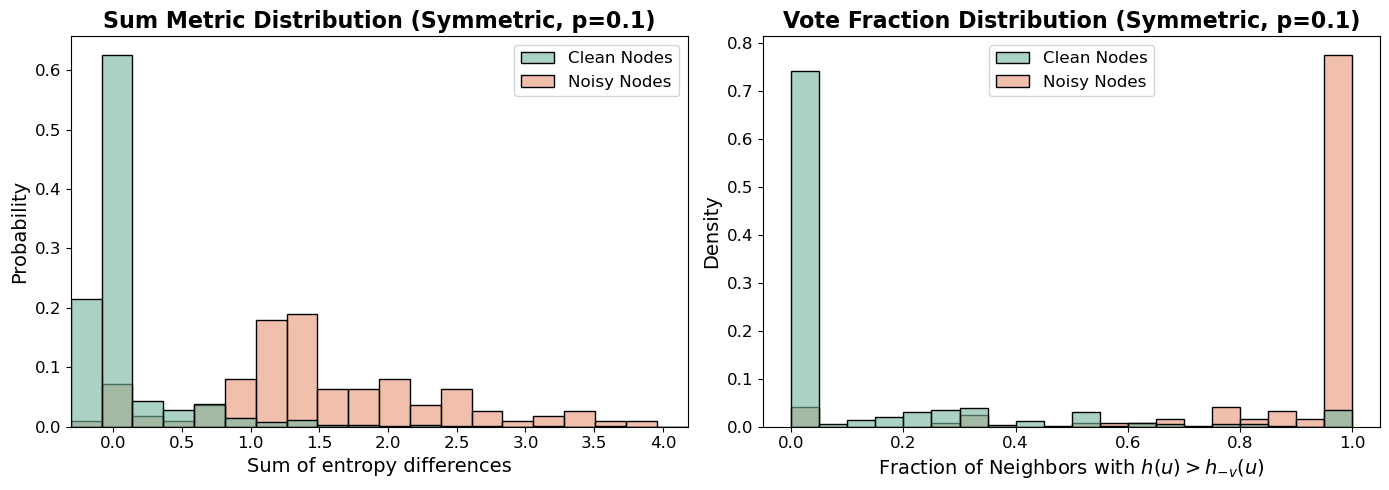

  Baseline GCN   -> Accuracy: 0.8582 ± 0.0041
  NLD Clean (Sum)  -> Accuracy: 0.8664 ± 0.0039
  NLD Clean (Vote) -> Accuracy: 0.8636 ± 0.0041

--- Training Set Noise level: 0.2 ---


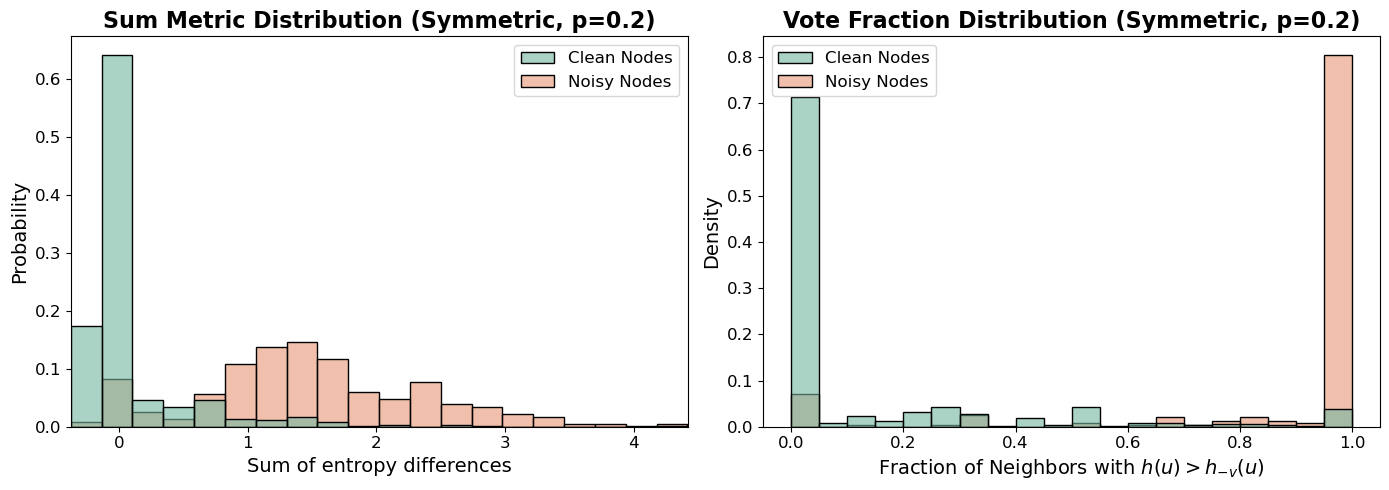

  Baseline GCN   -> Accuracy: 0.8462 ± 0.0043
  NLD Clean (Sum)  -> Accuracy: 0.8588 ± 0.0032
  NLD Clean (Vote) -> Accuracy: 0.8548 ± 0.0050

--- Training Set Noise level: 0.3 ---


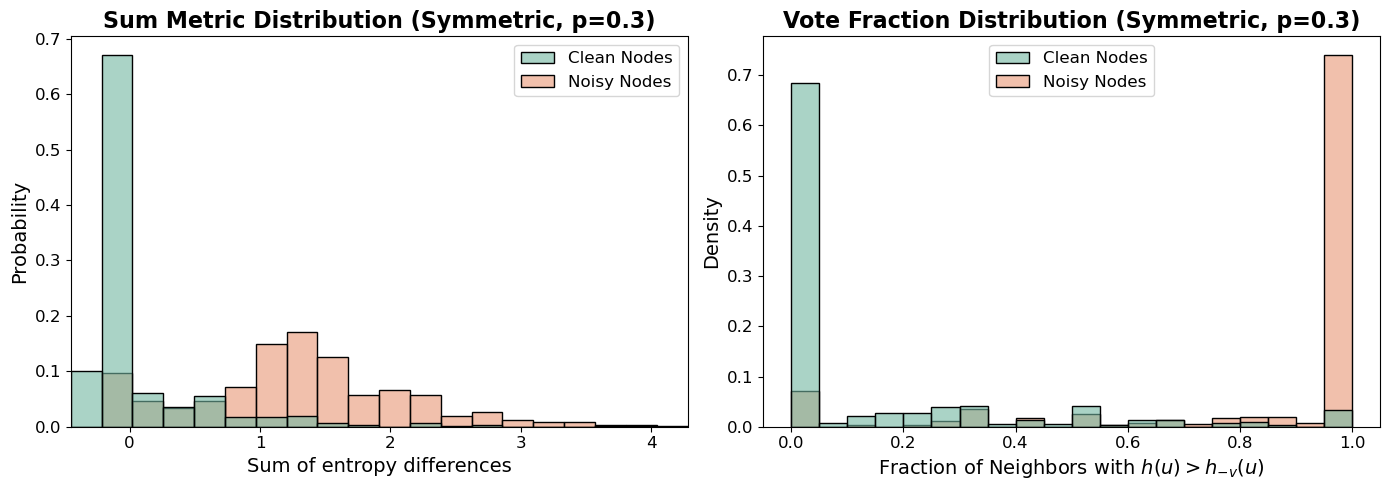

  Baseline GCN   -> Accuracy: 0.8296 ± 0.0149
  NLD Clean (Sum)  -> Accuracy: 0.8470 ± 0.0059
  NLD Clean (Vote) -> Accuracy: 0.8462 ± 0.0089

--- Training Set Noise level: 0.4 ---


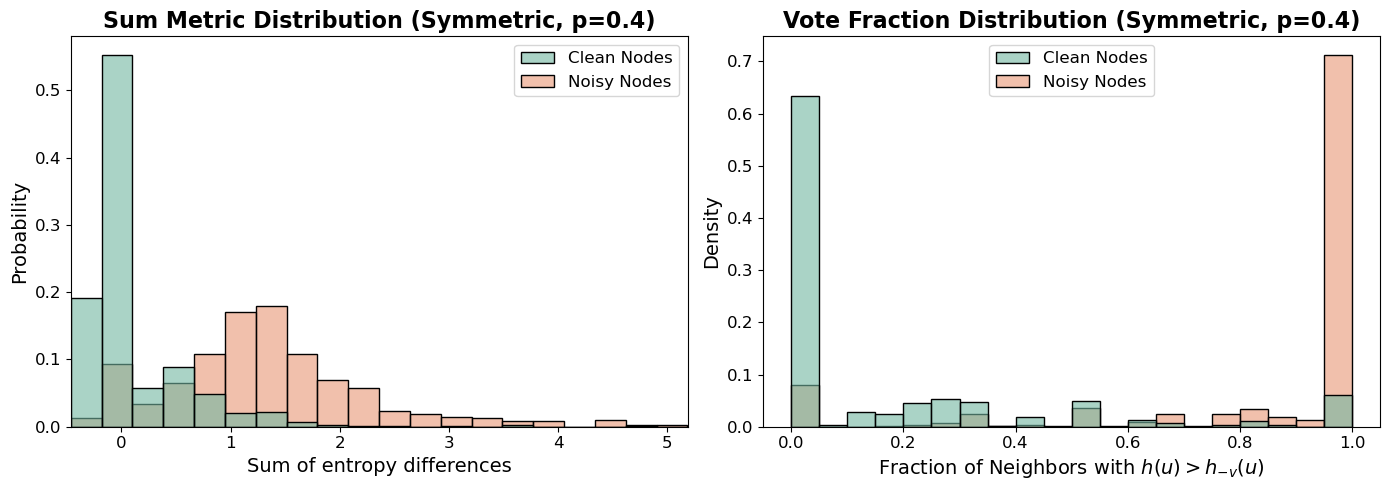

  Baseline GCN   -> Accuracy: 0.8122 ± 0.0088
  NLD Clean (Sum)  -> Accuracy: 0.8296 ± 0.0166
  NLD Clean (Vote) -> Accuracy: 0.8320 ± 0.0087

--- Training Set Noise level: 0.5 ---


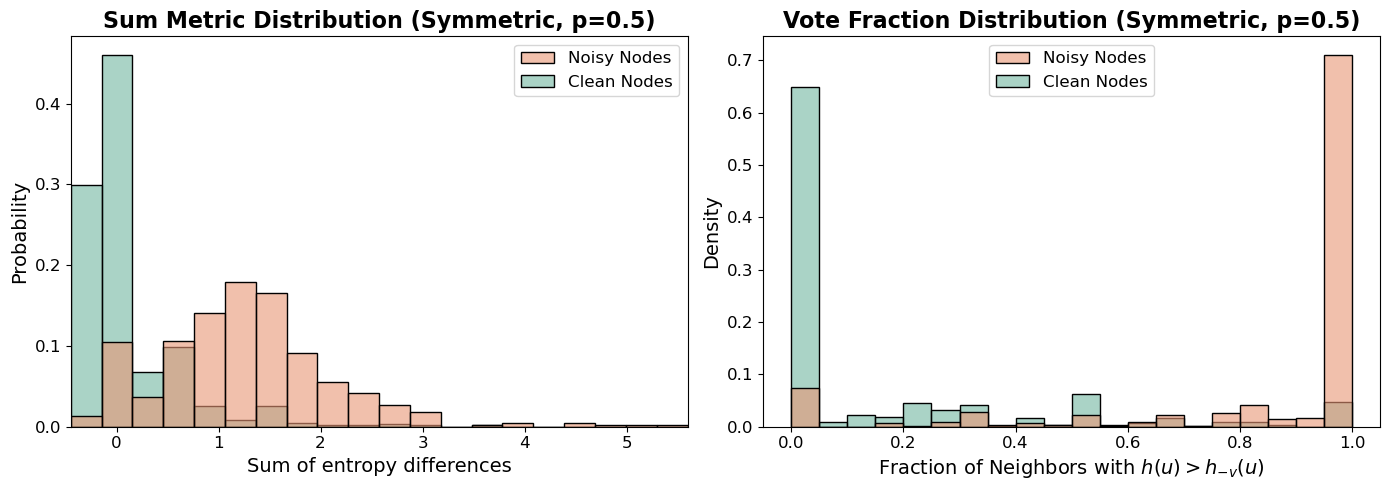

  Baseline GCN   -> Accuracy: 0.7678 ± 0.0090
  NLD Clean (Sum)  -> Accuracy: 0.7984 ± 0.0130
  NLD Clean (Vote) -> Accuracy: 0.8004 ± 0.0109


In [31]:


'''Execution'''
noise_rates = [0.1, 0.2, 0.3, 0.4, 0.5]
num_runs = 5
entropy_shield_limit = 1.2 

for noise_rate in noise_rates:
    acc_baseline = []
    acc_clean_sum = []
    acc_clean_vote = []
    
    print(f"\n--- Training Set Noise level: {noise_rate} ---")
    
    for run in range(num_runs):
        dataset = Planetoid(root='../influence/data/py311/Planetoid', split='full', name='Cora')
        data = dataset[0].to(device)
        data.edge_index, _ = add_remaining_self_loops(data.edge_index, num_nodes=data.num_nodes)

        num_classes = dataset.num_classes
        num_features = dataset.num_node_features
        # Inject noise ONLY into the training mask
        noisy_y = data.y.clone()
        noisy_y = corrupt_mask(noisy_y, data.train_mask, noise_rate, num_classes)
        noisy_y = corrupt_mask(noisy_y, data.val_mask, noise_rate, num_classes)

        
        # 1. Baseline Model
        baseline_model = GCNNet(num_features, 64, num_classes).to(device)
        baseline_test_acc, pred_baseline = train_and_evaluate(
            baseline_model, data.x, data.edge_index, noisy_y, 
            data.train_mask, data.val_mask, data.test_mask, data.y
        )
        acc_baseline.append(baseline_test_acc)

        # 2. Construct Fusion Labels (Noisy Train + Pseudo Val/Test)
        working_labels = pred_baseline.clone()
        working_labels[data.train_mask] = noisy_y[data.train_mask]

        # 3. Identify Noisy Nodes
        pred_noisy_sum, pred_noisy_vote, raw_sum, raw_vote = identify_noisy_nodes_realistic(
            data.edge_index, working_labels, data.num_nodes, num_classes,
            sum_threshold=0.0, vote_threshold=0.5, self_entropy_threshold=entropy_shield_limit
        )

        # Plot the distributions ONLY for the first run to avoid clutter
        if run == 0:
            plot_metric_distributions(
                raw_sum, raw_vote, data.train_mask, noisy_y, data.y, 
                noise_type="Symmetric", noise_rate=noise_rate
            )

        # 4. Clean Graph & Train Sum Variant
        clean_train_mask_sum = data.train_mask & ~pred_noisy_sum
        sum_model = GCNNet(num_features, 64, num_classes).to(device)
        sum_test_acc, _ = train_and_evaluate(
            sum_model, data.x, data.edge_index, noisy_y, 
            clean_train_mask_sum, data.val_mask, data.test_mask, data.y
        )
        acc_clean_sum.append(sum_test_acc)

        # 5. Clean Graph & Train Vote Variant
        clean_train_mask_vote = data.train_mask & ~pred_noisy_vote
        vote_model = GCNNet(num_features, 64, num_classes).to(device)
        vote_test_acc, _ = train_and_evaluate(
            vote_model, data.x, data.edge_index, noisy_y, 
            clean_train_mask_vote, data.val_mask, data.test_mask, data.y
        )
        acc_clean_vote.append(vote_test_acc)

    print(f"  Baseline GCN   -> Accuracy: {np.mean(acc_baseline):.4f} ± {np.std(acc_baseline):.4f}")
    print(f"  NLD Clean (Sum)  -> Accuracy: {np.mean(acc_clean_sum):.4f} ± {np.std(acc_clean_sum):.4f}")
    print(f"  NLD Clean (Vote) -> Accuracy: {np.mean(acc_clean_vote):.4f} ± {np.std(acc_clean_vote):.4f}")


--- Training Set Noise level: 0.1 ---


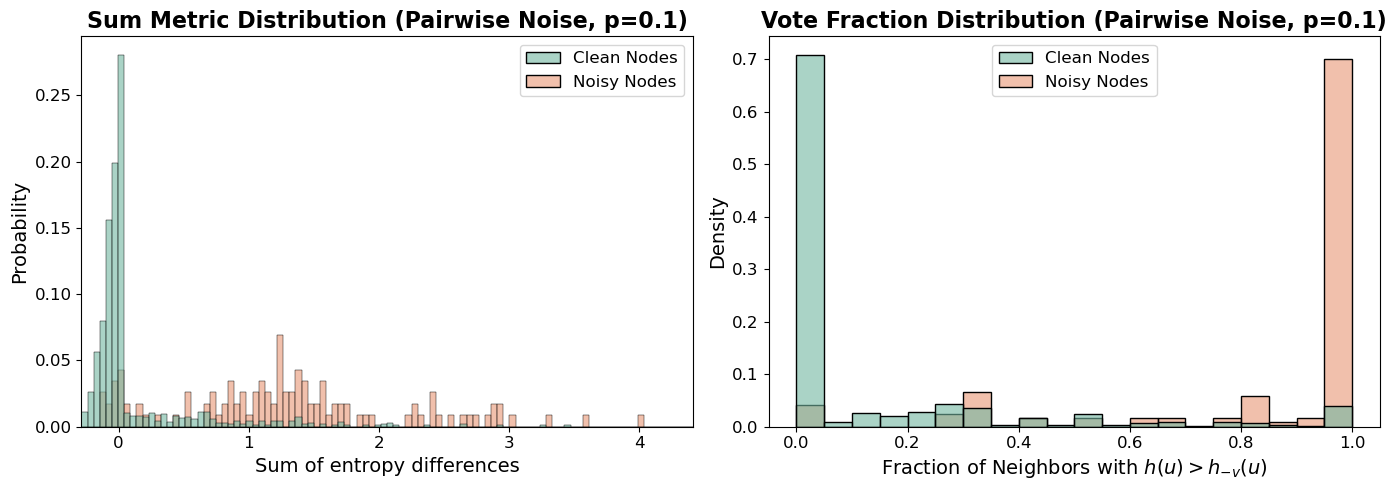

  Baseline GCN   -> Accuracy: 0.8472 ± 0.0107
  NLD Clean (Sum)  -> Accuracy: 0.8624 ± 0.0066
  NLD Clean (Vote) -> Accuracy: 0.8582 ± 0.0076

--- Training Set Noise level: 0.2 ---


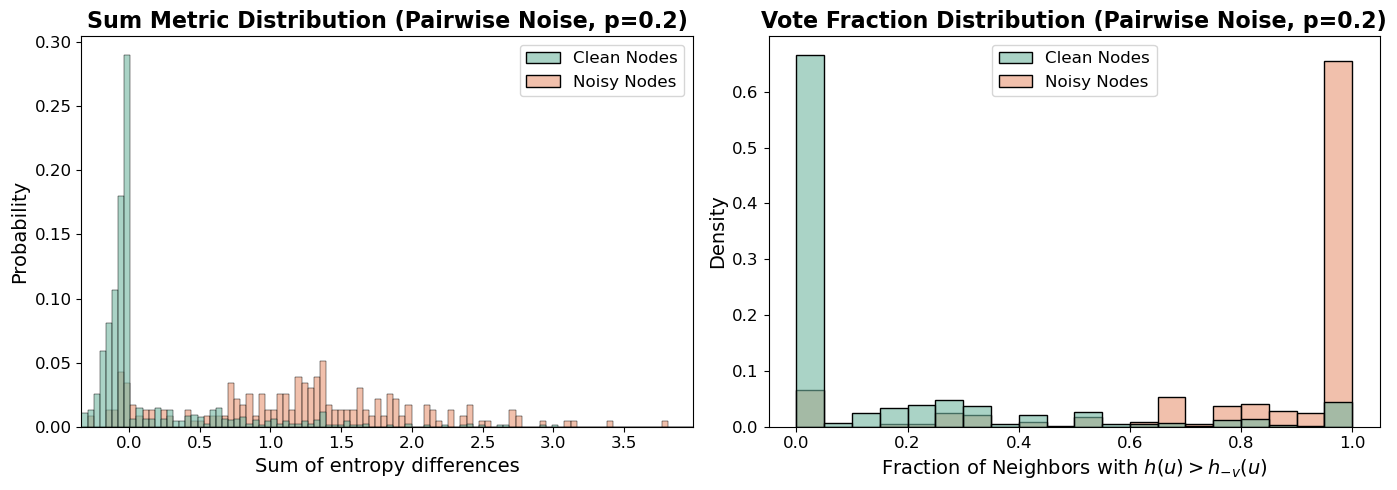

  Baseline GCN   -> Accuracy: 0.8170 ± 0.0102
  NLD Clean (Sum)  -> Accuracy: 0.8404 ± 0.0072
  NLD Clean (Vote) -> Accuracy: 0.8370 ± 0.0098

--- Training Set Noise level: 0.3 ---


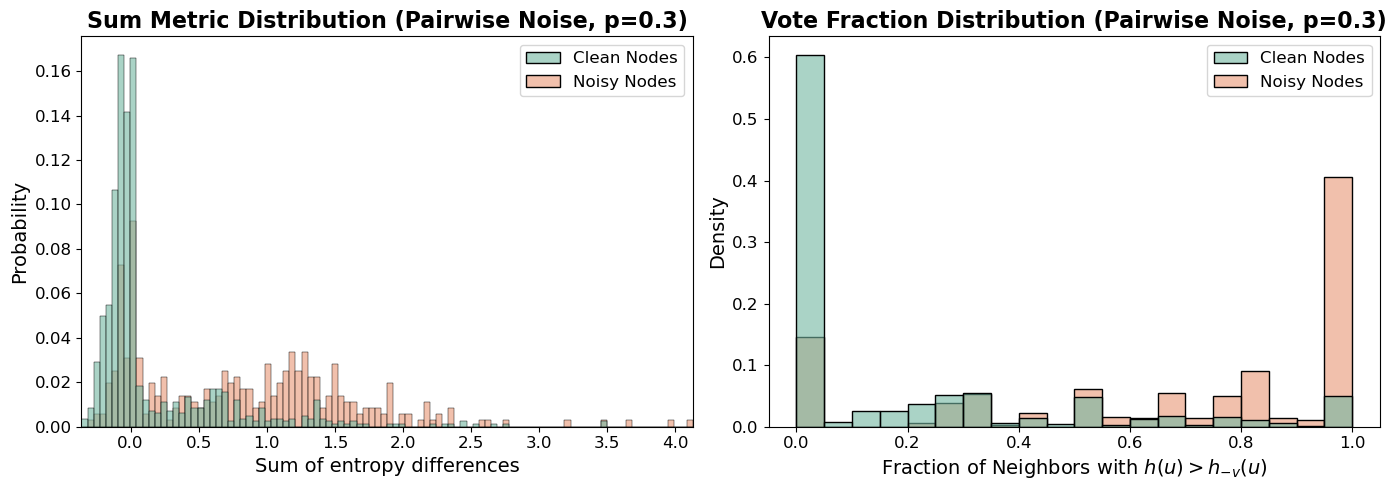

  Baseline GCN   -> Accuracy: 0.7284 ± 0.0314
  NLD Clean (Sum)  -> Accuracy: 0.7966 ± 0.0178
  NLD Clean (Vote) -> Accuracy: 0.7914 ± 0.0202

--- Training Set Noise level: 0.4 ---


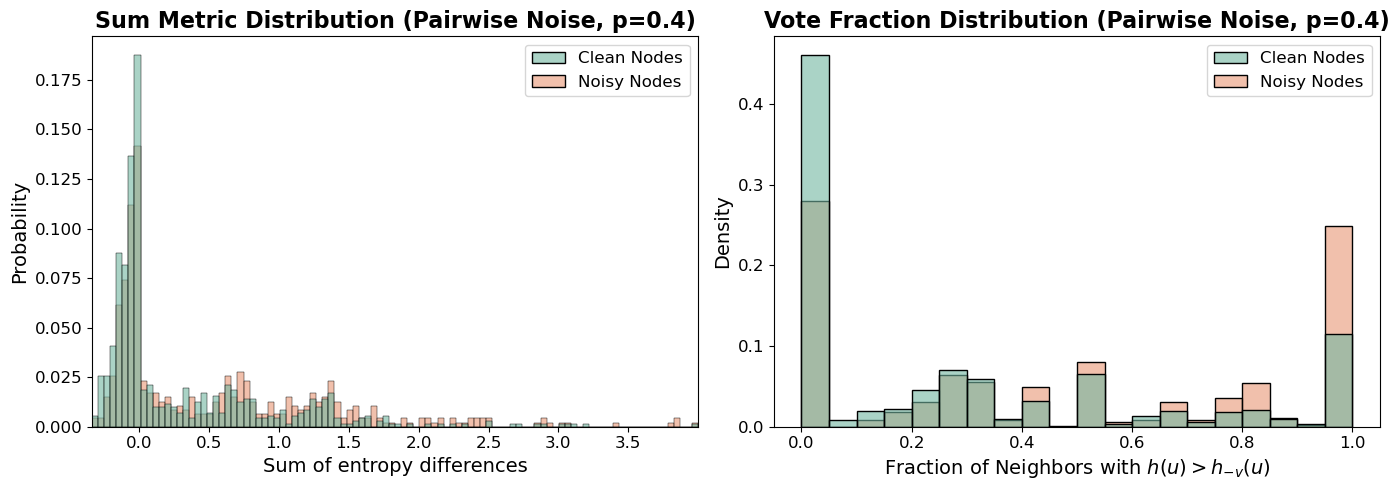

  Baseline GCN   -> Accuracy: 0.6306 ± 0.0221
  NLD Clean (Sum)  -> Accuracy: 0.6904 ± 0.0304
  NLD Clean (Vote) -> Accuracy: 0.6928 ± 0.0194


In [36]:


'''Execution'''
noise_rates = [0.1, 0.2, 0.3, 0.4]
num_runs = 5
entropy_shield_limit = 1.2 

for noise_rate in noise_rates:
    acc_baseline = []
    acc_clean_sum = []
    acc_clean_vote = []
    
    print(f"\n--- Training Set Noise level: {noise_rate} ---")
    
    for run in range(num_runs):
        dataset = Planetoid(root='../influence/data/py311/Planetoid', split='full', name='Cora')
        data = dataset[0].to(device)
        data.edge_index, _ = add_remaining_self_loops(data.edge_index, num_nodes=data.num_nodes)

        num_classes = dataset.num_classes
        num_features = dataset.num_node_features
        # Inject noise ONLY into the training mask
        noisy_y = data.y.clone()
        noisy_y = corrupt_mask_pairwise(noisy_y, data.train_mask, noise_rate, num_classes)
        noisy_y = corrupt_mask_pairwise(noisy_y, data.val_mask, noise_rate, num_classes)

        
        # 1. Baseline Model
        baseline_model = GCNNet(num_features, 64, num_classes).to(device)
        baseline_test_acc, pred_baseline = train_and_evaluate(
            baseline_model, data.x, data.edge_index, noisy_y, 
            data.train_mask, data.val_mask, data.test_mask, data.y
        )
        acc_baseline.append(baseline_test_acc)

        # 2. Construct Fusion Labels (Noisy Train + Pseudo Val/Test)
        working_labels = pred_baseline.clone()
        working_labels[data.train_mask] = noisy_y[data.train_mask]

        # 3. Identify Noisy Nodes
        pred_noisy_sum, pred_noisy_vote, raw_sum, raw_vote = identify_noisy_nodes_realistic(
            data.edge_index, working_labels, data.num_nodes, num_classes,
            sum_threshold=0.0, vote_threshold=0.5, self_entropy_threshold=entropy_shield_limit
        )

        # Plot the distributions ONLY for the first run to avoid clutter
        if run == 0:
            plot_metric_distributions(
                raw_sum, raw_vote, data.train_mask, noisy_y, data.y, 
                noise_type="Pairwise Noise", noise_rate=noise_rate
            )

        # 4. Clean Graph & Train Sum Variant
        clean_train_mask_sum = data.train_mask & ~pred_noisy_sum
        sum_model = GCNNet(num_features, 64, num_classes).to(device)
        sum_test_acc, _ = train_and_evaluate(
            sum_model, data.x, data.edge_index, noisy_y, 
            clean_train_mask_sum, data.val_mask, data.test_mask, data.y
        )
        acc_clean_sum.append(sum_test_acc)

        # 5. Clean Graph & Train Vote Variant
        clean_train_mask_vote = data.train_mask & ~pred_noisy_vote
        vote_model = GCNNet(num_features, 64, num_classes).to(device)
        vote_test_acc, _ = train_and_evaluate(
            vote_model, data.x, data.edge_index, noisy_y, 
            clean_train_mask_vote, data.val_mask, data.test_mask, data.y
        )
        acc_clean_vote.append(vote_test_acc)

    print(f"  Baseline GCN   -> Accuracy: {np.mean(acc_baseline):.4f} ± {np.std(acc_baseline):.4f}")
    print(f"  NLD Clean (Sum)  -> Accuracy: {np.mean(acc_clean_sum):.4f} ± {np.std(acc_clean_sum):.4f}")
    print(f"  NLD Clean (Vote) -> Accuracy: {np.mean(acc_clean_vote):.4f} ± {np.std(acc_clean_vote):.4f}")